## Підбор параметра parallelCutoff (поріг за якого (якщо розмір даних на кроці рекурсії меньше нього) переходить в послідовну гілку) звичайного послідовного Фільтр-Крускала
**Зафіксовані параметри під час підбору:**

- `threads`: 12
- `threshold` (базовий випадок в послідовному): 8192
- `partitionBlock` (розмір 1 блоку для паралельного розбиття): 65536
- `filterBlock` (розмір 1 блоку для паралельної фільтрації): 16384
- `parallelSortCutoff` (поріг, коли включається паралельне сортування): 0 — значить, що паралельного сортування не буде

`parallelCutoff` підбирався на параметрах: 32768, 65536, 131072, 262144, 524288, 1048576.

Для вибору значення параметра на кожному графі з понад мільйоном ребер обчислювався відносний час - відношення середнього часу виконання при цьому значенні до найменшого середнього часу на цьому графі (1,00 відповідає найкращому значенню). Обиралося значення з найменшим середнім геометричним відносного часу по всіх графах. Додатково враховувалися найбільший відносний час (найгірший граф) і кількість графів, на яких значення було найкращим. Типовий розкид часу між повторами однієї конфігурації становив близько 1,4%. Якщо середні геометричні відносного часу для двох значень параметра відрізнялися менше, ніж на цю величину, такі значення вважалися рівноцінними, оскільки різниця між ними може бути випадковою.

### Обране значення parallelCutoff: `131072`

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv("C:/Users/admin/source/repos/Kruskal/results/fk_par_cutoff.csv")
MIN_EDGES = 1_000_000          

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   series           2484 non-null   object 
 1   graph            2484 non-null   object 
 2   family           2484 non-null   object 
 3   algorithm        2484 non-null   object 
 4   threads          2484 non-null   int64  
 5   threshold        2484 non-null   int64  
 6   partition_block  2130 non-null   float64
 7   filter_block     2130 non-null   float64
 8   par_cutoff       2130 non-null   float64
 9   psort_cutoff     2130 non-null   float64
 10  V                2484 non-null   int64  
 11  E                2484 non-null   int64  
 12  E_over_V         2484 non-null   float64
 13  seed             2484 non-null   int64  
 14  repeat           2484 non-null   int64  
 15  total_ms         2484 non-null   float64
 16  sort_ms          0 non-null      float64
 17  dsu_ms        

In [21]:
# Параметри досліду
PARAMS = ["threads", "threshold", "partition_block", "filter_block", "par_cutoff", "psort_cutoff"]

def experiment_params(df):
    rows = {}
    for alg, d in df.groupby("algorithm", sort=False):
        row = {}
        for c in PARAMS:
            vals = sorted(d[c].dropna().unique())
            row[c] = ", ".join(str(int(v)) for v in vals) if vals else "-"
        repeats = d.groupby(["graph"] + PARAMS, dropna=False)["repeat"].nunique()
        row["повторів"] = f"{repeats.min()}–{repeats.max()}" if repeats.min() != repeats.max() else str(repeats.min())
        rows[alg] = row
    graphs = df["graph"].unique()
    print(f"Графи ({len(graphs)}): {', '.join(graphs)}")
    return pd.DataFrame(rows).T

display(experiment_params(df))

Графи (19): B1, B2, B3, B4, B5, B6, B7, B8, B9, B10, B11, G1, C1, C2, C3, C4, C5, C6, C7


,threads,threshold,partition_block,filter_block,par_cutoff,psort_cutoff,повторів
fk,1,8192,-,-,-,-,6–25
fk-par,12,8192,65536,16384,"32768, 65536, 131072, 262144, 524288, 1048576",0,7–25


In [5]:
graphs = (
    df[["series", "graph", "V", "E"]]
    .drop_duplicates()
    .sort_values(["series", "V", "E"])
    .reset_index(drop=True)
)

display(graphs)

,series,graph,V,E
0,density,B1,8000,16000
1,density,B2,8000,32000
2,density,B3,8000,64000
3,density,B4,8000,128000
4,density,B5,8000,256000
5,density,B6,8000,512000
6,density,B7,8000,1024000
7,density,B8,8000,2048000
8,density,B9,8000,4096000
9,density,B10,8000,8192000


In [4]:
order = list(df["graph"].unique())   # порядок графів як у плані

In [5]:
# 1. Середній час: послідовний FK і fk-par для кожного порогу
seq = df[df["algorithm"] == "fk"].groupby("graph")["total_ms"].mean()

par = df[df["algorithm"] == "fk-par"].copy()
par["par_cutoff"] = par["par_cutoff"].astype(int)
t = par.groupby(["graph", "E", "par_cutoff"], as_index=False)["total_ms"].mean()

t["speedup"] = t["graph"].map(seq) / t["total_ms"]                          # прискорення відносно послідовного FK
t["rel"] = t["total_ms"] / t.groupby("graph")["total_ms"].transform("min")   # 1.00 = найкращий поріг на графі

print("Середній час fk-par, мс:")
display(t.pivot(index="graph", columns="par_cutoff", values="total_ms").reindex(order).round(1))

Середній час fk-par, мс:


par_cutoff,32768,65536,131072,262144,524288,1048576
graph,,,,,,
B1,0.9,0.9,0.9,0.9,0.9,0.9
B2,1.1,1.1,1.1,1.2,1.1,1.1
B3,2.0,1.4,1.4,1.4,1.4,1.4
B4,3.3,3.2,2.4,2.4,2.4,2.3
B5,4.6,4.4,4.3,3.5,3.6,3.5
B6,6.9,6.7,6.1,6.1,6.6,6.7
B7,11.4,11.4,10.9,10.8,13.0,12.5
B8,20.5,20.8,20.2,19.8,21.6,24.0
B9,39.1,39.5,38.8,39.5,39.9,41.8


In [6]:
print("Прискорення відносно послідовного FK:")
display(t.pivot(index="graph", columns="par_cutoff", values="speedup").reindex(order).round(2))

Прискорення відносно послідовного FK:


par_cutoff,32768,65536,131072,262144,524288,1048576
graph,,,,,,
B1,0.96,1.01,1.00,0.99,0.97,1.01
B2,0.99,0.99,0.99,0.93,0.98,0.98
B3,0.80,1.15,1.13,1.13,1.14,1.13
B4,0.70,0.73,0.97,0.98,0.97,1.02
B5,0.77,0.80,0.81,0.99,0.98,1.00
B6,0.96,0.98,1.09,1.08,1.00,0.99
B7,1.07,1.07,1.12,1.13,0.94,0.98
B8,1.24,1.22,1.26,1.28,1.18,1.06
B9,1.23,1.22,1.24,1.22,1.21,1.15


In [7]:
# %% 2. Висновок: лише великі графи
big = t[t["E"] >= MIN_EDGES]
print(f"Графи з E >= {MIN_EDGES:,}: {', '.join(g for g in order if g in set(big['graph']))}")

rel_table = big.pivot(index="graph", columns="par_cutoff", values="rel").reindex([g for g in order if g in set(big['graph'])])
print("Відносний час (1.00 = найкращий поріг на цьому графі):")
display(rel_table.round(3))

Графи з E >= 1,000,000: B7, B8, B9, B10, B11, G1, C4, C5, C6, C7
Відносний час (1.00 = найкращий поріг на цьому графі):


par_cutoff,32768,65536,131072,262144,524288,1048576
graph,,,,,,
B7,1.062,1.056,1.008,1.000,1.211,1.157
B8,1.035,1.050,1.020,1.000,1.088,1.211
B9,1.008,1.019,1.000,1.019,1.028,1.079
B10,1.000,1.032,1.027,1.018,1.019,1.071
B11,1.007,1.000,1.007,1.026,1.007,1.014
G1,1.127,1.008,1.000,1.026,1.057,1.117
C4,1.207,1.095,1.024,1.000,1.019,1.054
C5,1.179,1.065,1.000,1.027,1.145,1.122
C6,1.113,1.018,1.000,1.043,1.049,1.085


In [8]:
summary = (big.groupby("par_cutoff")["rel"]
              .agg(середнє_відставання=lambda r: np.exp(np.log(r).mean()),   # середнє геометричне
                   найгірший_граф="max",
                   перемог=lambda r: int((r == 1.0).sum()))
              .sort_values("середнє_відставання"))
display(summary.round(3))

,середнє_відставання,найгірший_граф,перемог
par_cutoff,,,
131072,1.009,1.027,5
262144,1.018,1.043,3
65536,1.036,1.095,1
524288,1.065,1.211,0
32768,1.077,1.207,1
1048576,1.098,1.211,0


In [9]:
best = summary.index[0]
print(f"\nНайкращий поріг паралельності: {best}")
print(f"Він повільніший за найкращий на кожному графі в середньому на {100 * (summary.iloc[0, 0] - 1):.1f}%")
if 262144 in summary.index:
    gap = 100 * (summary.loc[262144, "середнє_відставання"] / summary.iloc[0, 0] - 1)
    print(f"Поточне значення 262144 гірше за найкраще на {gap:.1f}%")



Найкращий поріг паралельності: 131072
Він повільніший за найкращий на кожному графі в середньому на 0.9%
Поточне значення 262144 гірше за найкраще на 0.9%


In [10]:
noise = (par[par["E"] >= MIN_EDGES].groupby(["graph", "par_cutoff"])["total_ms"]
            .agg(lambda x: x.std() / x.mean()).median() * 100)
print(f"Типовий розкид між повторами: {noise:.1f}%  (різниця, менша за нього - це шум)")

Типовий розкид між повторами: 1.7%  (різниця, менша за нього, — це шум)


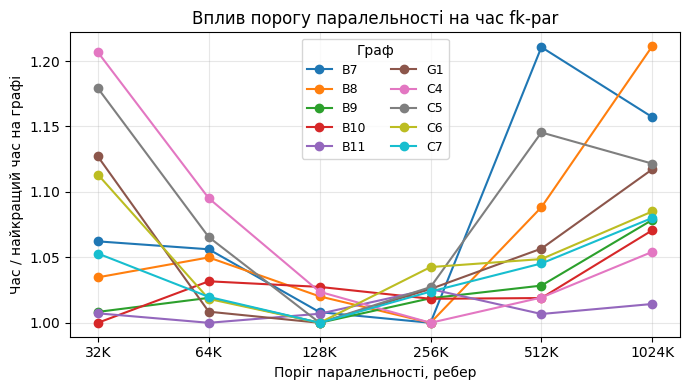

In [12]:
# %% 3. Графік: відносний час від порогу для кожного великого графа
fig, ax = plt.subplots(figsize=(7, 4))
for graph, row in rel_table.iterrows():
    ax.plot(row.index, row.values, marker="o", label=graph)
ax.set_xscale("log", base=2)
ax.set_xticks(rel_table.columns, [f"{c // 1024}K" for c in rel_table.columns])
ax.set_xlabel("Поріг паралельності, ребер")
ax.set_ylabel("Час / найкращий час на графі")
ax.set_title("Вплив порогу паралельності на час fk-par")
ax.grid(alpha=0.3)
ax.legend(title="Граф", ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig("C:/Users/admin/source/repos/Kruskal/results/fk_par_cutoff.png", dpi=150)
plt.show()